# Feature engineering geoespacial — AirPrice

Genera variables geoespaciales sobre el dataset limpio: **distancia al centro y a POIs** de Londres, y **clustering espacial (K-Means)** sobre las coordenadas. Exporta el dataset enriquecido a `data/processed/airprice_features.csv`.

No usa `price_clean` ni `price_range` para construir las features (sin fuga de datos) y respeta la misma semilla/split de `src/utils.py`.

In [3]:
import sys
sys.path.append("../..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.utils import (
    DATA_DIR,
    REPORTS_DIR,
    SEED,
    cargar_dataset,
    fijar_semilla,
    split_estratificado,
)
from src.preprocessing import descartar_columnas
from src.features import (
    distancia_centro,
    distancia_pois,
    evaluar_k,
    clustering_espacial,
)

sns.set_theme(style="whitegrid")
fijar_semilla(SEED)

RUTA_FEATURES = DATA_DIR / "processed" / "airprice_features.csv"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

## 1. Distancias a centro y POIs

Se calcula la distancia Haversine (km) al centro de Londres y a cada punto de interés.

In [4]:
df = cargar_dataset()
print("Filas:", df.shape[0])

df = distancia_centro(df)
df = distancia_pois(df)

columnas_distancia = [c for c in df.columns if c.startswith("distancia_")]
df[columnas_distancia].describe().T

Filas: 61617


,count,mean,std,min,25%,50%,75%,max
distancia_centro_km,61617.0,7.665653,5.092280,0.011382,3.853151,6.226723,10.558459,28.772274
distancia_heathrow_km,61617.0,23.551534,7.037600,0.229317,19.009954,23.045260,27.595258,51.721844
distancia_kings_cross_km,61617.0,7.976982,5.198359,0.019216,4.223473,6.780326,10.743800,29.405194
distancia_hyde_park_km,61617.0,7.876465,5.322680,0.195939,3.674756,6.685470,11.012433,31.320141
distancia_canary_wharf_km,61617.0,10.481738,5.513247,0.079456,6.663330,9.865613,13.243299,35.255482


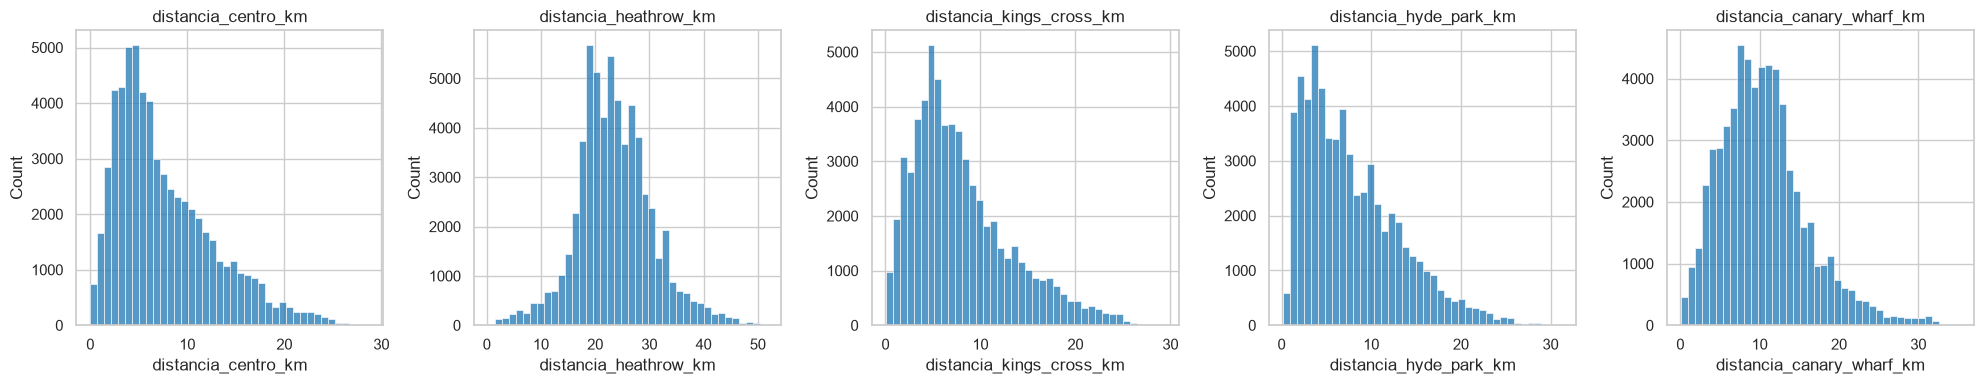

In [ ]:
""" Gráfico: histogramas de las distancias geoespaciales (km).
Un panel por cada columna 'distancia_*' (centro, Heathrow, King's Cross,
Hyde Park, Canary Wharf).
Eje X: distancia en kilómetros al punto de interés.
Eje Y: frecuencia (n.º de alojamientos) por rango de distancia.
Uso: ver la dispersión/ubicación típica respecto a cada POI; una cola a
la derecha indica pocos alojamientos muy alejados del punto."""

fig, axes = plt.subplots(
    1, len(columnas_distancia), figsize=(4 * len(columnas_distancia), 4)
)
for ax, col in zip(axes, columnas_distancia):
    sns.histplot(df[col], bins=40, ax=ax, color="#1f77b4")
    ax.set_title(col)

plt.tight_layout()
plt.savefig(REPORTS_DIR / "features_distancias.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Clustering espacial (selección de k)

Se elige el número de clusters con el método del codo y el coeficiente de silueta, usando una muestra del conjunto de entrenamiento para mayor rapidez.

In [6]:
df_modelo = descartar_columnas(df)
X_train, X_val, X_test, y_train, y_val, y_test = split_estratificado(
    df_modelo,
    target="price_range",
    excluir=["price_clean", "id"],
    seed=SEED,
)

muestra = X_train.sample(n=min(3000, len(X_train)), random_state=SEED)
resultados_k = evaluar_k(muestra, ks=range(2, 11), seed=SEED)
resultados_k

,k,inercia,silueta
0,2,22.024189,0.401523
1,3,15.546265,0.359167
2,4,12.071032,0.346848
3,5,9.846311,0.356208
4,6,8.417391,0.346017
5,7,7.459138,0.336395
6,8,6.656901,0.327788
7,9,5.903747,0.343159
8,10,5.259501,0.351271


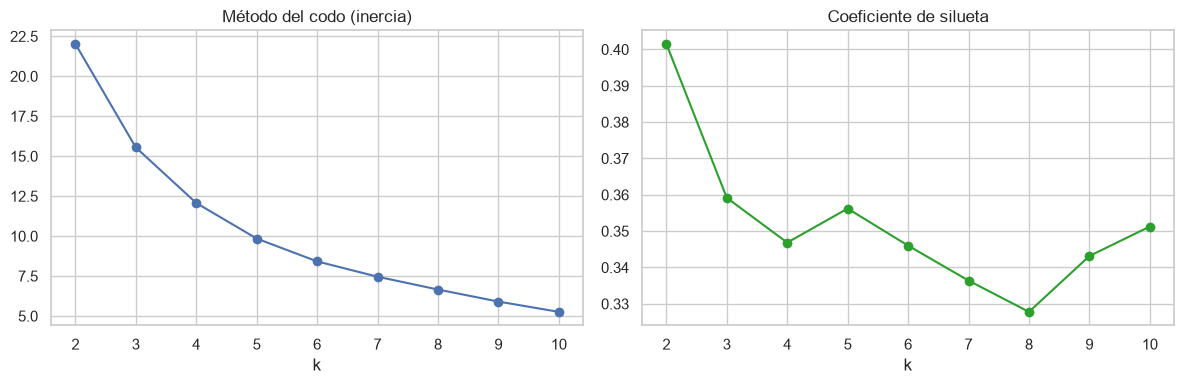

k con mayor silueta: 2


In [ ]:
""" Gráficos de selección de k (K-Means).
 Izquierda - Método del codo:
 Eje X: k (n.º de clusters). Eje Y: inercia (suma de distancias a los
 centroides). Se busca el "codo" donde la inercia deja de bajar rápido.
 Derecha - Coeficiente de silueta:
 Eje X: k. Eje Y: silueta media (rango [-1, 1]); más alto = clusters mejor
 separados. Se elige el k con mayor silueta."""
 
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(resultados_k["k"], resultados_k["inercia"], marker="o")
axes[0].set_title("Método del codo (inercia)")
axes[0].set_xlabel("k")

axes[1].plot(
    resultados_k["k"], resultados_k["silueta"], marker="o", color="#2ca02c"
)
axes[1].set_title("Coeficiente de silueta")
axes[1].set_xlabel("k")

plt.tight_layout()
plt.savefig(REPORTS_DIR / "features_seleccion_k.png", dpi=150, bbox_inches="tight")
plt.show()

mejor_k = int(resultados_k.loc[resultados_k["silueta"].idxmax(), "k"])
print("k con mayor silueta:", mejor_k)

Se ajusta K-Means **solo con el conjunto de entrenamiento** y se asigna el cluster a todas las filas.

In [8]:
df_features, modelo_kmeans = clustering_espacial(
    df, X_train, k=mejor_k, seed=SEED
)

print("Clusters:", df_features["cluster_zona"].nunique())
df_features["cluster_zona"].value_counts()

Clusters: 2


cluster_zona
1    35644
0    25973
Name: count, dtype: int64

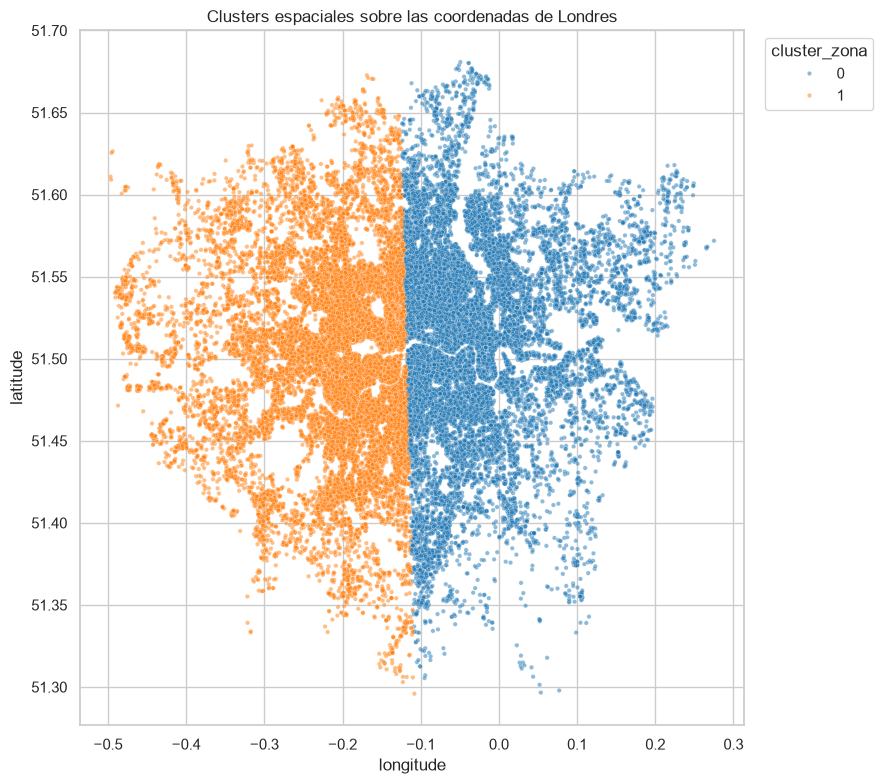

In [ ]:
""" Gráfico: dispersión de alojamientos por coordenada y su cluster.
 Eje X: longitud (longitude). Eje Y: latitud (latitude).
 Cada punto es un alojamiento; el color (hue) indica el 'cluster_zona'
 asignado por K-Means. Uso: verificar que los clusters forman zonas
 geográficas coherentes de Londres (centro vs. periferia)."""

plt.figure(figsize=(9, 8))
sns.scatterplot(
    data=df_features,
    x="longitude",
    y="latitude",
    hue="cluster_zona",
    palette="tab10",
    s=10,
    alpha=0.5,
)
plt.title("Clusters espaciales sobre las coordenadas de Londres")
plt.legend(title="cluster_zona", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(REPORTS_DIR / "features_clusters.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Exportar dataset

Se guarda el dataset con las columnas `distancia_*` y `cluster_zona` para su uso posterior en los modelos.

In [ ]:
df_features.to_csv(RUTA_FEATURES, index=False, encoding="utf-8")

print("Dataset enriquecido guardado en: data/processed")
print("Filas:", df_features.shape[0])
print("Columnas geoespaciales:", columnas_distancia + ["cluster_zona"])